# I. Chấn đoán bệnh tiểu đường

## 1. Định nghĩa bài toán

Đầu vào là các thông tin sức khỏe và đặc điểm của một bản ghi. Đầu ra `diabetes` có hai lớp: `0` và `1`. Đây là **phân loại nhị phân**. Ta so sánh ba thuật toán ML truyền thống với một mạng neural có hai hidden layer. Tiêu chí chọn mô hình là **F1 trên Validation**, vì lớp 1 ít hơn lớp 0; Test chỉ dùng để đánh giá cuối.

## 2. Nguồn dữ liệu

Bộ dữ liệu được sử dụng trong bài toán là: `diabetes_dataset.csv` (https://www.kaggle.com/datasets/priyamchoksi/100000-diabetes-clinical-dataset).

Dữ liệu chứa các thông tin như:

- Năm thu thập dữ liệu.
- Giới tính.
- Tuổi.
- Khu vực sinh sống.
- Chủng tộc.
- Tăng huyết áp.
- Bệnh tim.
- Lịch sử hút thuốc.
- BMI.
- HbA1c.
- Mức đường huyết.
- Trạng thái mắc bệnh tiểu đường.

Biến `diabetes` được sử dụng làm biến mục tiêu.

## 3. Tải dữ liệu


In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
np.random.seed(SEED)
DATA_PATH = Path("diabetes_dataset.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path(r'C:\Users\Dat\Downloads\PTHTTM\DATA\diabetes_dataset.csv')

df = pd.read_csv(DATA_PATH)
print("Kích thước:", df.shape)
display(df.head())

Kích thước: (100000, 16)


,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


## 4. Kiểm tra dữ liệu

Xem kiểu dữ liệu, số lượng và thống kê mô tả để biết cột nào là số, cột nào là chữ. Bảng thống kê không tự chứng minh dữ liệu đúng; nó chỉ giúp phát hiện những điểm cần kiểm tra.

In [2]:
display(pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Giá trị thiếu": df.isna().sum(),
    "Số giá trị khác nhau": df.nunique(dropna=True)
}))
display(df.describe(include="all").T)

,Kiểu dữ liệu,Giá trị thiếu,Số giá trị khác nhau
year,int64,0,7
gender,str,0,3
age,float64,0,102
location,str,0,55
race:AfricanAmerican,int64,0,2
race:Asian,int64,0,2
race:Caucasian,int64,0,2
race:Hispanic,int64,0,2
race:Other,int64,0,2
hypertension,int64,0,2


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,100000.0,NaN,NaN,NaN,2018.36082,1.345239,2015.0,2019.0,2019.0,2019.0,2022.0
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
location,100000,55,Hawaii,2038,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race:AfricanAmerican,100000.0,NaN,NaN,NaN,0.20223,0.401665,0.0,0.0,0.0,0.0,1.0
race:Asian,100000.0,NaN,NaN,NaN,0.20015,0.400114,0.0,0.0,0.0,0.0,1.0
race:Caucasian,100000.0,NaN,NaN,NaN,0.19876,0.399069,0.0,0.0,0.0,0.0,1.0
race:Hispanic,100000.0,NaN,NaN,NaN,0.19888,0.39916,0.0,0.0,0.0,0.0,1.0
race:Other,100000.0,NaN,NaN,NaN,0.19998,0.399987,0.0,0.0,0.0,0.0,1.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0


## 5. Phân tích chất lượng dữ liệu

Kiểm tra dữ liệu thiếu, trùng và giá trị ngoài phạm vi hợp lý. Những giá trị vượt phạm vi cần được xem xét, không mặc nhiên coi mọi ngoại lệ là dữ liệu sai.

In [3]:
quality_report = pd.DataFrame({
    "Thiếu": df.isna().sum(),
    "Tỷ lệ thiếu (%)": df.isna().mean() * 100,
    "Số giá trị khác nhau": df.nunique(dropna=True)
})
display(quality_report.round(2))
print("Dòng trùng hoàn toàn:", df.duplicated().sum())

,Thiếu,Tỷ lệ thiếu (%),Số giá trị khác nhau
year,0,0.0,7
gender,0,0.0,3
age,0,0.0,102
location,0,0.0,55
race:AfricanAmerican,0,0.0,2
race:Asian,0,0.0,2
race:Caucasian,0,0.0,2
race:Hispanic,0,0.0,2
race:Other,0,0.0,2
hypertension,0,0.0,2


Dòng trùng hoàn toàn: 14


## 6. Phân tích giá trị thiếu

Chỉ loại dòng khi nhãn không hợp lệ. Nếu đặc trưng bị thiếu, giá trị điền sẽ được học từ **Train** trong bước tiền xử lý, không tính từ toàn bộ dữ liệu.

In [4]:
missing = df.isna().sum().reset_index()
missing.columns = ["Cột", "Số giá trị thiếu"]
display(missing[missing["Số giá trị thiếu"] > 0])
print("Tổng số ô thiếu:", int(df.isna().sum().sum()))

,Cột,Số giá trị thiếu


Tổng số ô thiếu: 0


## 7. Phân tích dữ liệu trùng lặp

Loại các dòng trùng hoàn toàn trước khi chia dữ liệu để cùng một dòng không xuất hiện nhiều lần. Không loại các bản ghi chỉ vì chúng có cùng tuổi hoặc cùng BMI.

In [5]:
before = len(df)
df = df.drop_duplicates().copy()
print("Trước:", before)
print("Sau:", len(df))
print("Đã loại:", before - len(df))

Trước: 100000
Sau: 99986
Đã loại: 14


## 8. Phân tích giá trị không hợp lệ

Kiểm tra nhãn 0/1 và một số giới hạn cơ bản của tuổi, BMI và chỉ số xét nghiệm. Giữ các giá trị hợp lệ; những giá trị thiếu ở đặc trưng sẽ được xử lý sau. Đây là quy tắc làm sạch phục vụ bài học, không phải bộ tiêu chuẩn y khoa đầy đủ.

In [6]:
checks = {
    "Nhãn khác 0/1": (~df["diabetes"].isin([0, 1])).sum(),
    "Tuổi ngoài 0–120": ((df["age"] < 0) | (df["age"] > 120)).sum(),
    "BMI không dương": (df["bmi"] <= 0).sum(),
    "HbA1c không dương": (df["hbA1c_level"] <= 0).sum(),
    "Glucose không dương": (df["blood_glucose_level"] <= 0).sum()
}
display(pd.DataFrame(list(checks.items()), columns=["Kiểm tra", "Số dòng"]))

df = df[df["diabetes"].isin([0, 1])].copy()
for col in ["age", "bmi", "hbA1c_level", "blood_glucose_level"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df[(df["age"].isna() | df["age"].between(0, 120)) &
        (df["bmi"].isna() | (df["bmi"] > 0)) &
        (df["hbA1c_level"].isna() | (df["hbA1c_level"] > 0)) &
        (df["blood_glucose_level"].isna() | (df["blood_glucose_level"] > 0))].copy()
df["diabetes"] = df["diabetes"].astype(int)
print("Còn lại:", len(df), "dòng")

,Kiểm tra,Số dòng
0,Nhãn khác 0/1,0
1,Tuổi ngoài 0–120,0
2,BMI không dương,0
3,HbA1c không dương,0
4,Glucose không dương,0


Còn lại: 99986 dòng


## 9. Phân tích ngoại lệ

Boxplot cho thấy trung vị, khoảng tứ phân vị và các điểm nằm xa phần lớn dữ liệu. Một điểm nằm ngoài râu hộp **không nhất thiết là sai**. Không xóa ngoại lệ hàng loạt chỉ để làm đẹp biểu đồ.

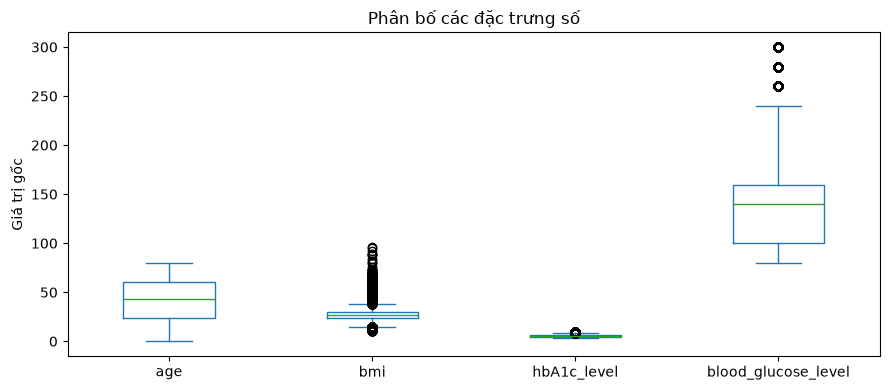

In [7]:
cols = ["age", "bmi", "hbA1c_level", "blood_glucose_level"]
df[cols].plot(kind="box", figsize=(9, 4), title="Phân bố các đặc trưng số")
plt.ylabel("Giá trị gốc")
plt.tight_layout()
plt.show()

**Giải thích biểu đồ:** Các biến có đơn vị và thang đo khác nhau nên không so sánh trực tiếp độ cao hộp. BMI hoặc glucose có thể có giá trị lớn hơn phần lớn mẫu; cần kiểm tra ý nghĩa và chất lượng nguồn trước khi quyết định xử lý.

## 10. Phân tích khám phá dữ liệu (EDA)

Quan sát phân bố nhãn và các đặc trưng quan trọng. Phân bố mất cân bằng là lý do cần xem Recall, F1 và các đường ROC/Precision–Recall, không chỉ Accuracy.

,Nhãn,Số dòng,Tỷ lệ (%)
0,0,91486,91.5
1,1,8500,8.5


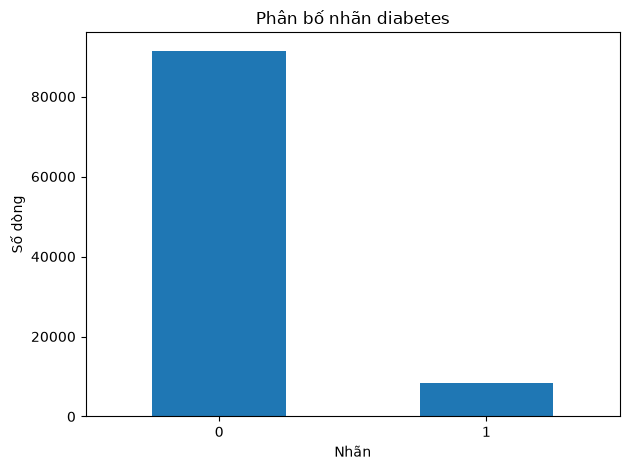

In [8]:
counts = df["diabetes"].value_counts().sort_index()
display(pd.DataFrame({"Nhãn": counts.index, "Số dòng": counts.values,
                      "Tỷ lệ (%)": (counts.values / len(df) * 100).round(2)}))
counts.plot(kind="bar", rot=0, title="Phân bố nhãn diabetes")
plt.xlabel("Nhãn")
plt.ylabel("Số dòng")
plt.tight_layout()
plt.show()

**Giải thích biểu đồ:** Cột 0 cao hơn cột 1 cho thấy dữ liệu mất cân bằng. Một mô hình luôn đoán 0 có thể đạt Accuracy cao nhưng không phát hiện được lớp 1.

,age,bmi,hbA1c_level,blood_glucose_level
diabetes,,,,
0,40.11,26.89,5.40,132.85
1,60.95,31.99,6.93,194.09


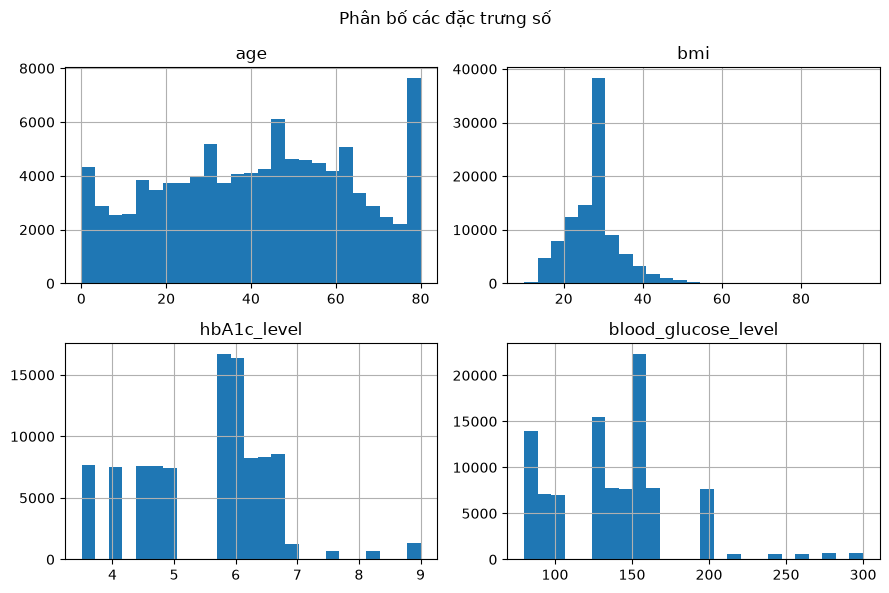

In [9]:
display(df.groupby("diabetes")[cols].mean().round(2))
df[cols].hist(figsize=(9, 6), bins=25)
plt.suptitle("Phân bố các đặc trưng số")
plt.tight_layout()
plt.show()

**Giải thích biểu đồ:** Histogram cho biết vùng giá trị xuất hiện nhiều và độ lệch của phân phối. Bảng trung bình giúp so sánh hai nhóm, nhưng không chứng minh quan hệ nhân quả. Các giá trị xét nghiệm có thể liên quan rất mạnh đến nhãn; cần thận trọng nếu dùng mô hình vào mục đích dự đoán trước khi có xét nghiệm.

## 11. Xác định đặc trưng và biến mục tiêu

`X` gồm các cột đầu vào, `y` là nhãn `diabetes`. Không đưa nhãn vào đặc trưng. Giữ các cột gốc của notebook mẫu để dễ đối chiếu; những thuộc tính nhạy cảm như chủng tộc/giới tính chỉ được dùng trong bài thực nghiệm và cần đánh giá riêng trước khi áp dụng thực tế.

In [10]:
TARGET = "diabetes"
X = df.drop(columns=[TARGET])
y = df[TARGET]
print("X:", X.shape, "| y:", y.shape)

X: (99986, 15) | y: (99986,)


## 12. Biểu diễn dữ liệu

Một dòng là một vector đặc trưng. Sau mã hóa cột chữ, toàn bộ dữ liệu trở thành ma trận số có kích thước `N × d`. `N` là số mẫu, `d` là số đặc trưng sau xử lý.

In [11]:
display(df.iloc[[0]])
print("Số đặc trưng gốc:", X.shape[1])
print("Vector gốc của mẫu đầu:", X.iloc[0].to_dict())

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0


Số đặc trưng gốc: 15
Vector gốc của mẫu đầu: {'year': 2020, 'gender': 'Female', 'age': 32.0, 'location': 'Alabama', 'race:AfricanAmerican': 0, 'race:Asian': 0, 'race:Caucasian': 0, 'race:Hispanic': 0, 'race:Other': 1, 'hypertension': 0, 'heart_disease': 0, 'smoking_history': 'never', 'bmi': 27.32, 'hbA1c_level': 5.0, 'blood_glucose_level': 100}


## 13. Feature Engineering

Giữ đúng hai đặc trưng đơn giản trong notebook mẫu: `cardio_risk` và `glucose_hba1c_interaction`. Đây chỉ là phép biến đổi từ dữ liệu đầu vào, **không sử dụng nhãn**. Tên `cardio_risk` là tên đặc trưng của bài học, không phải thang điểm nguy cơ lâm sàng.

In [12]:
def add_features(data):
    data = data.copy()
    data["cardio_risk"] = data["hypertension"] + data["heart_disease"]
    data["glucose_hba1c_interaction"] = data["blood_glucose_level"] * data["hbA1c_level"]
    return data

X = add_features(X)
print("Số đặc trưng sau khi tạo thêm:", X.shape[1])

Số đặc trưng sau khi tạo thêm: 17


## 14. Train / Validation / Test Split

Chia theo tỷ lệ **70% / 15% / 15%**, có `stratify=y` để giữ tỷ lệ hai lớp gần nhau. Train dùng để học, Validation dùng để chọn mô hình, Test để đánh giá cuối. Tất cả bốn mô hình dùng cùng một lần chia.

In [13]:
from sklearn.model_selection import train_test_split

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

split_table = pd.DataFrame([
    {"Tập dữ liệu": name, "Số dòng": len(yy),
     "Lớp 0": int((yy == 0).sum()), "Lớp 1": int((yy == 1).sum()),
     "Tỷ lệ lớp 1 (%)": yy.mean() * 100}
    for name, yy in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]
])
display(split_table.style.format({"Số dòng": "{:,.0f}", "Lớp 0": "{:,.0f}",
                                  "Lớp 1": "{:,.0f}", "Tỷ lệ lớp 1 (%)": "{:.2f}%"}))

,Tập dữ liệu,Số dòng,Lớp 0,Lớp 1,Tỷ lệ lớp 1 (%)
0,Train,"69,990","64,040","5,950",8.50%
1,Validation,"14,998","13,723","1,275",8.50%
2,Test,"14,998","13,723","1,275",8.50%


## 15. Preprocessing pipeline

Cột số được điền thiếu bằng trung vị rồi chuẩn hóa; cột chữ được điền bằng giá trị phổ biến nhất rồi One-Hot Encoding. **Chỉ fit trên Train**, sau đó dùng cùng bộ xử lý cho Validation và Test. Cách này cũng giúp mọi mô hình nhận cùng một ma trận đầu vào.

$$
x' = \frac{x-\mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}
$$

Trong đó $\mu_{\mathrm{train}}$ và $\sigma_{\mathrm{train}}$ là trung bình và độ lệch chuẩn tính từ Train. Dùng dữ liệu Test để tính các giá trị này sẽ gây rò rỉ thông tin.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_cols = X_train_raw.select_dtypes(include="number").columns.tolist()
category_cols = X_train_raw.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False)), category_cols)
])

X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
X_val = preprocessor.transform(X_val_raw).astype(np.float32)
X_test = preprocessor.transform(X_test_raw).astype(np.float32)
d = X_train.shape[1]
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Số đặc trưng sau mã hóa:", d)

Train: (69990, 78) | Validation: (14998, 78) | Test: (14998, 78)
Số đặc trưng sau mã hóa: 78


## 16. Baseline model

Baseline luôn dự đoán lớp phổ biến nhất. Đây là **mốc tham khảo**, không tính vào bốn mô hình được so sánh. Nó giúp thấy vì sao Accuracy cao có thể gây hiểu nhầm trên dữ liệu mất cân bằng.

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_val)
print("Baseline Accuracy:", round(accuracy_score(y_val, baseline_pred), 4))
print("Baseline Recall:", round(recall_score(y_val, baseline_pred, zero_division=0), 4))

Baseline Accuracy: 0.915
Baseline Recall: 0.0


## 17. Model training

Ba ML dùng scikit-learn; mạng Deep Learning được tự viết bằng NumPy. Không dùng class tự xây dựng, không dùng autograd và không có hệ thống huấn luyện nhiều kiến trúc.

Một hàm đánh giá chung giúp lưu kết quả vào bảng. Với ngưỡng $0.5$:

$$
\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}
$$

$$
\mathrm{Precision}=\frac{TP}{TP+FP},\qquad \mathrm{Recall}=\frac{TP}{TP+FN}
$$

$$
F_1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}
$$

**ROC-AUC** đánh giá khả năng xếp hạng hai lớp qua nhiều ngưỡng. **PR-AUC** trong notebook là Average Precision. Các chỉ số này không phải tỷ lệ dự đoán đúng.

In [16]:
def evaluate(y_true, score):
    pred = (np.asarray(score).reshape(-1) >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, score),
        "PR-AUC": average_precision_score(y_true, score)
    }

trained_models = {}
val_scores = {}
val_results = []

### 17.1. ML 1 - Logistic Regression

Mô hình tuyến tính dùng làm mốc ML cơ bản. `max_iter=1000` là giới hạn số vòng tối ưu, không phải số hidden layer.

In [17]:
from sklearn.linear_model import LogisticRegression

logistic = LogisticRegression(max_iter=1000, random_state=SEED)
logistic.fit(X_train, y_train)
score = logistic.predict_proba(X_val)[:, 1]
trained_models["Logistic Regression"] = logistic
val_scores["Logistic Regression"] = score
val_results.append({"Model": "Logistic Regression", **evaluate(y_val, score)})
display(pd.DataFrame([val_results[-1]]).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.9617,0.8804,0.6353,0.738,0.9621,0.8191


### 17.2. ML 2 - Decision Tree

Cây quyết định học các điều kiện chia dữ liệu. Giới hạn độ sâu và số mẫu tối thiểu ở lá để giảm nguy cơ học thuộc. Đây là cấu hình cơ sở, chưa phải tối ưu tham số.

In [18]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEED)
tree.fit(X_train, y_train)
score = tree.predict_proba(X_val)[:, 1]
trained_models["Decision Tree"] = tree
val_scores["Decision Tree"] = score
val_results.append({"Model": "Decision Tree", **evaluate(y_val, score)})
display(pd.DataFrame([val_results[-1]]).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Decision Tree,0.9725,0.9954,0.6792,0.8075,0.9735,0.8628


### 17.3. ML 3 - Random Forest

Random Forest kết hợp nhiều cây. Dùng 100 cây và giới hạn độ sâu để bài chạy tương đối nhanh trên máy cá nhân.

In [19]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=100, max_depth=12,
                                min_samples_leaf=5, random_state=SEED, n_jobs=-1)
forest.fit(X_train, y_train)
score = forest.predict_proba(X_val)[:, 1]
trained_models["Random Forest"] = forest
val_scores["Random Forest"] = score
val_results.append({"Model": "Random Forest", **evaluate(y_val, score)})
display(pd.DataFrame([val_results[-1]]).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.9724,1.0,0.6753,0.8062,0.9668,0.8672


### 17.4. Deep Learning - MLP 

Theo tài liệu NumPy, dùng hai hidden layer: **$d\to16\to8\to1$**. `d` là số đặc trưng sau mã hóa. Hidden layer dùng ReLU, đầu ra dùng Sigmoid.

$$
H_1=\operatorname{ReLU}(XW_1+b_1)
$$

$$
H_2=\operatorname{ReLU}(H_1W_2+b_2)
$$

$$
\hat{y}=\sigma(H_2W_3+b_3)
$$

Với batch $N$ dòng: $H_1\in\mathbb{R}^{N\times16}$, $H_2\in\mathbb{R}^{N\times8}$, đầu ra có kích thước $N\times1$. Đây là các biểu diễn do mạng học, không phải 16 hoặc 8 đặc trưng do người lập trình đặt tên.

In [20]:
rng = np.random.default_rng(SEED)
W1 = (rng.standard_normal((d, 16)) * np.sqrt(2 / d)).astype(np.float32)
b1 = np.zeros((1, 16), dtype=np.float32)
W2 = (rng.standard_normal((16, 8)) * np.sqrt(2 / 16)).astype(np.float32)
b2 = np.zeros((1, 8), dtype=np.float32)
W3 = (rng.standard_normal((8, 1)) * np.sqrt(2 / 8)).astype(np.float32)
b3 = np.zeros((1, 1), dtype=np.float32)

print("Kiến trúc:", d, "→ 16 → 8 → 1")
print("W1:", W1.shape, "W2:", W2.shape, "W3:", W3.shape)
print("Số tham số:", sum(a.size for a in [W1, b1, W2, b2, W3, b3]))

Kiến trúc: 78 → 16 → 8 → 1
W1: (78, 16) W2: (16, 8) W3: (8, 1)
Số tham số: 1409


#### Forward và Loss

ReLU giữ giá trị dương, đưa giá trị âm về 0. Sigmoid biến đầu ra thành điểm trong khoảng 0–1. Binary Cross-Entropy đo mức sai lệch giữa nhãn thật và điểm dự đoán:

$$
L=-\frac{1}{N}\sum_{i=1}^{N}\left[y_i\log(\hat{y}_i)+(1-y_i)\log(1-\hat{y}_i)\right]
$$

`clip` tránh lỗi số học khi tính log. Không dùng hàm loss hoặc forward của framework Deep Learning.

In [21]:
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -50, 50)))

def forward(X):
    z1 = X @ W1 + b1
    h1 = relu(z1)
    z2 = h1 @ W2 + b2
    h2 = relu(z2)
    z3 = h2 @ W3 + b3
    y_hat = sigmoid(z3)
    cache = {"X": X, "z1": z1, "h1": h1, "z2": z2,
             "h2": h2, "y_hat": y_hat}
    return y_hat, cache

def binary_cross_entropy(y, p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-12, 1 - 1e-12)
    y = np.asarray(y).reshape(-1, 1)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

p_demo, cache_demo = forward(X_train[:4])
print("H1:", cache_demo["h1"].shape, "| H2:", cache_demo["h2"].shape,
      "| Đầu ra:", p_demo.shape)

H1: (4, 16) | H2: (4, 8) | Đầu ra: (4, 1)


#### Backpropagation và Gradient Descent

Backpropagation tính gradient từ lớp cuối về lớp đầu bằng quy tắc dây chuyền. Với Sigmoid và Binary Cross-Entropy:

$$
dZ_3=\frac{\hat{Y}-Y}{N}
$$

$$
dW_3=H_2^T dZ_3,\qquad dH_2=dZ_3W_3^T
$$

$$
dZ_2=dH_2\odot\operatorname{ReLU}'(Z_2)
$$

Các lớp trước làm tương tự. Sau đó cập nhật trọng số:

$$
W\leftarrow W-\eta\,\frac{\partial L}{\partial W}
$$

Trong đó $\eta$ là learning rate. Các đạo hàm bên dưới được viết trực tiếp bằng NumPy.

In [22]:
def backward(y, cache):
    X = cache["X"]
    z1, h1 = cache["z1"], cache["h1"]
    z2, h2 = cache["z2"], cache["h2"]
    y = np.asarray(y, dtype=np.float32).reshape(-1, 1)
    n = len(y)

    dz3 = (cache["y_hat"] - y) / n
    dW3 = h2.T @ dz3
    db3 = dz3.sum(axis=0, keepdims=True)

    dh2 = dz3 @ W3.T
    dz2 = dh2 * (z2 > 0)
    dW2 = h1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)

    dh1 = dz2 @ W2.T
    dz1 = dh1 * (z1 > 0)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)
    return dW1, db1, dW2, db2, dW3, db3

print("Kích thước gradient:", [g.shape for g in backward(y_train.iloc[:4], cache_demo)])

Kích thước gradient: [(78, 16), (1, 16), (16, 8), (1, 8), (8, 1), (1, 1)]


#### Huấn luyện mạng

Mỗi epoch đi qua Train theo các mini-batch. Trình tự vẫn là **Forward → Loss → Backward → Update**. Dùng 100 epoch, batch size 1024 và learning rate 0.05 để giữ thời gian chạy hợp lý. Không dùng class, scheduler, early stopping hay nhiều kiến trúc trong bài so sánh này. Loss được ghi sau mỗi epoch để vẽ biểu đồ.

In [23]:
EPOCHS = 100
BATCH_SIZE = 1024
LEARNING_RATE = 0.05
Y_train = y_train.to_numpy(dtype=np.float32).reshape(-1, 1)
Y_val = y_val.to_numpy(dtype=np.float32).reshape(-1, 1)
loss_history = []
val_loss_history = []

for epoch in range(EPOCHS):
    indices = rng.permutation(len(X_train))
    for start in range(0, len(indices), BATCH_SIZE):
        idx = indices[start:start + BATCH_SIZE]
        y_hat, cache = forward(X_train[idx])
        dW1, db1, dW2, db2, dW3, db3 = backward(Y_train[idx], cache)
        W1 -= LEARNING_RATE * dW1
        b1 -= LEARNING_RATE * db1
        W2 -= LEARNING_RATE * dW2
        b2 -= LEARNING_RATE * db2
        W3 -= LEARNING_RATE * dW3
        b3 -= LEARNING_RATE * db3

    train_loss = binary_cross_entropy(Y_train, forward(X_train)[0])
    val_loss = binary_cross_entropy(Y_val, forward(X_val)[0])
    loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1:3d}: Train loss={train_loss:.4f}, Val loss={val_loss:.4f}")

mlp_val_score = forward(X_val)[0].ravel()
val_scores["MLP NumPy"] = mlp_val_score
val_results.append({"Model": "MLP NumPy", **evaluate(y_val, mlp_val_score)})
display(pd.DataFrame([val_results[-1]]).round(4))

Epoch  20: Train loss=0.1144, Val loss=0.1166
Epoch  40: Train loss=0.1105, Val loss=0.1126
Epoch  60: Train loss=0.1067, Val loss=0.1087
Epoch  80: Train loss=0.1033, Val loss=0.1054
Epoch 100: Train loss=0.1004, Val loss=0.1025


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,MLP NumPy,0.9665,0.9396,0.6471,0.7664,0.9645,0.8439


#### Biểu đồ quá trình học

Train loss giảm cho thấy mạng đang giảm lỗi trên dữ liệu huấn luyện. Validation loss giúp kiểm tra khả năng tổng quát hóa. Nếu Train tiếp tục giảm nhưng Validation tăng rõ, có thể mạng đang overfit. Một đường loss giảm không tự chứng minh mô hình tốt trên Test.

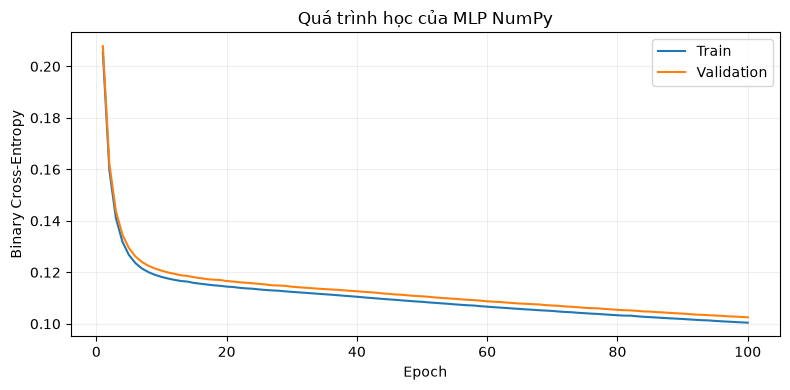

Train loss: 0.2055 → 0.1004
Validation loss: 0.2079 → 0.1025


In [24]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), loss_history, label="Train")
plt.plot(range(1, EPOCHS + 1), val_loss_history, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.title("Quá trình học của MLP NumPy")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print(f"Train loss: {loss_history[0]:.4f} → {loss_history[-1]:.4f}")
print(f"Validation loss: {val_loss_history[0]:.4f} → {val_loss_history[-1]:.4f}")

Train loss và Validation loss đều giảm trong lần chạy này. Mức cuối lần lượt là **0.1004** và **0.1025**; hai đường không tách xa rõ ở cuối quá trình. Điều đó cho thấy mạng đang học, nhưng không tự chứng minh khả năng tổng quát hóa trên dữ liệu khác.

## 18. Model comparison

Lưu bảng Validation của đúng bốn mô hình. **Chọn theo F1 trên Validation trước khi xem Test**; khi bằng F1, dùng ROC-AUC để phân biệt. Không chọn mô hình bằng Accuracy đơn lẻ.

In [25]:
comparison_df = pd.DataFrame(val_results).sort_values(
    ["F1", "ROC-AUC"], ascending=False).reset_index(drop=True)
display(comparison_df.style.format({c: "{:.4f}" for c in comparison_df.columns if c != "Model"}))

best_model_name = comparison_df.iloc[0]["Model"]
print("Mô hình được chọn theo Validation F1:", best_model_name)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Decision Tree,0.9725,0.9954,0.6792,0.8075,0.9735,0.8628
1,Random Forest,0.9724,1.0000,0.6753,0.8062,0.9668,0.8672
2,MLP NumPy,0.9665,0.9396,0.6471,0.7664,0.9645,0.8439
3,Logistic Regression,0.9617,0.8804,0.6353,0.7380,0.9621,0.8191


Mô hình được chọn theo Validation F1: Decision Tree


**Nhận xét kết quả Validation:** Decision Tree có F1 cao nhất (0.8075). Random Forest có PR-AUC cao nhất (0.8672). MLP NumPy đạt F1 = 0.7664. Vì tiêu chí đã chọn là F1, ta giữ **Decision Tree** để đánh giá cuối; không đổi tiêu chí theo mô hình đang dẫn đầu.

### 18.1. Biểu đồ so sánh năm metrics

Mỗi nhóm cột là một chỉ số. Cột cao hơn nghĩa là điểm chỉ số đó lớn hơn; tuy nhiên Precision và Recall có thể đánh đổi nhau, nên không cộng các cột để chọn mô hình. Đặc biệt, Accuracy cao có thể đi kèm Recall thấp.

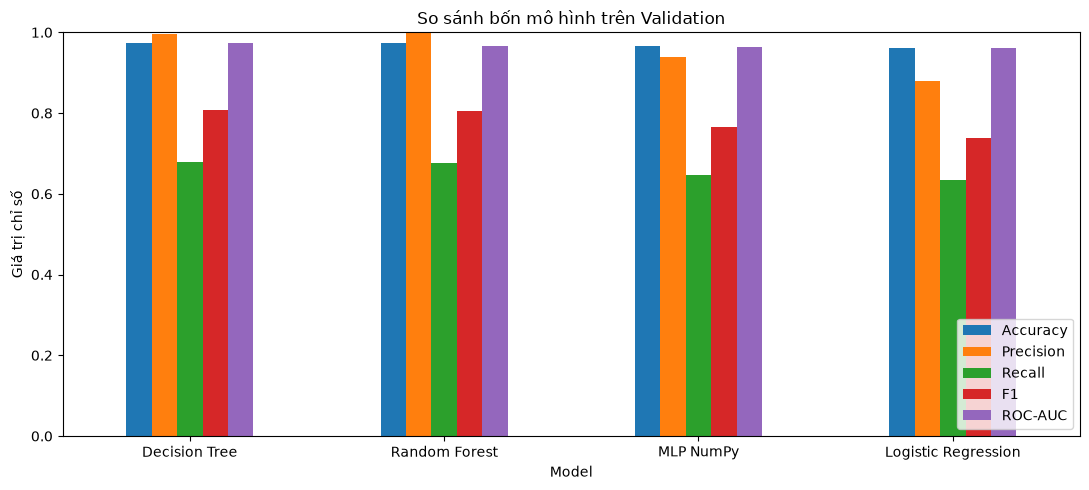

In [26]:
comparison_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0)
plt.ylabel("Giá trị chỉ số")
plt.title("So sánh bốn mô hình trên Validation")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 19. Evaluation - Đánh giá trên Test

Sau khi đã chọn mô hình bằng Validation, đánh giá **cả bốn mô hình** trên cùng Test và ngưỡng 0.5. Kết quả Test chỉ dùng để báo cáo, không dùng để chọn lại mô hình. ROC-AUC và PR-AUC dùng điểm xác suất, không dùng nhãn dự đoán 0/1.

In [27]:
mlp_weights = {"W1": W1.copy(), "b1": b1.copy(),
               "W2": W2.copy(), "b2": b2.copy(),
               "W3": W3.copy(), "b3": b3.copy()}

def predict_dl(X, p):
    h1 = relu(X @ p["W1"] + p["b1"])
    h2 = relu(h1 @ p["W2"] + p["b2"])
    return sigmoid(h2 @ p["W3"] + p["b3"]).ravel()

test_scores = {}
for name, model in trained_models.items():
    test_scores[name] = model.predict_proba(X_test)[:, 1]
test_scores["MLP NumPy"] = predict_dl(X_test, mlp_weights)

test_results = pd.DataFrame([
    {"Model": name, **evaluate(y_test, score)}
    for name, score in test_scores.items()
])
display(test_results.style.format({c: "{:.4f}" for c in test_results.columns if c != "Model"}))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.9605,0.8692,0.6306,0.7309,0.9582,0.8087
1,Decision Tree,0.9707,0.9976,0.6573,0.7924,0.9704,0.8480
2,Random Forest,0.9705,1.0000,0.6533,0.7903,0.9640,0.8579
3,MLP NumPy,0.9647,0.9347,0.6290,0.7520,0.9603,0.8293


**Nhận xét Test:** Decision Tree đạt Accuracy = 0.9707, Precision = 0.9976, Recall = 0.6573, F1 = 0.7924. MLP NumPy đạt F1 = 0.7520. Accuracy cao không có nghĩa là phát hiện hết lớp 1; cần đọc thêm Recall và số FN.

### 19.1. ROC và Precision–Recall

**ROC:** trục ngang là False Positive Rate, trục dọc là True Positive Rate. Đường gần góc trên trái hơn thường tốt hơn. **Precision–Recall:** phù hợp để xem khả năng phát hiện lớp dương hiếm. Đường ngang biểu thị tỷ lệ lớp 1; PR-AUC càng cao càng tốt, nhưng không thay thế F1 tại ngưỡng 0.5.

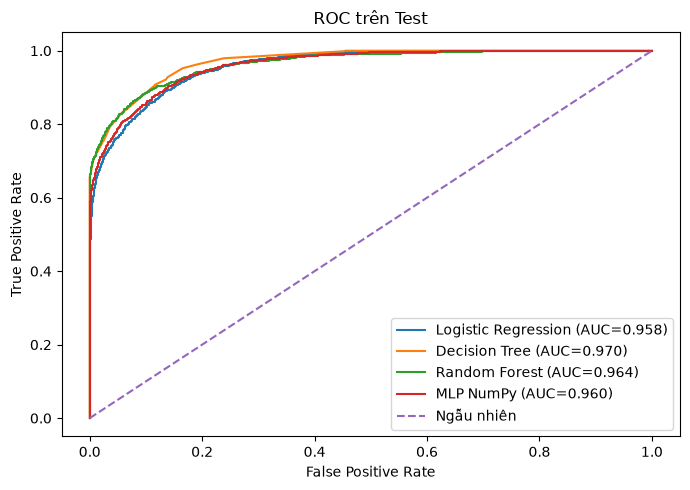

In [28]:
plt.figure(figsize=(7, 5))
for name, score in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    auc = roc_auc_score(y_test, score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Ngẫu nhiên")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC trên Test")
plt.legend()
plt.tight_layout()
plt.show()

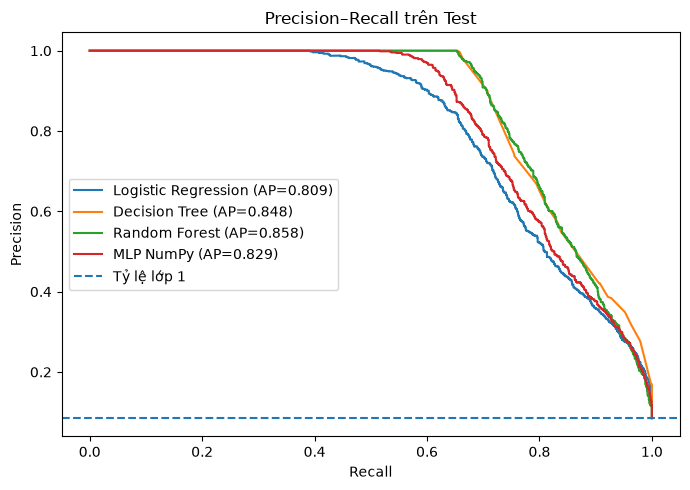

In [29]:
plt.figure(figsize=(7, 5))
for name, score in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, score)
    ap = average_precision_score(y_test, score)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
plt.axhline(y_test.mean(), linestyle="--", label="Tỷ lệ lớp 1")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall trên Test")
plt.legend()
plt.tight_layout()
plt.show()

### 19.2. Confusion matrix

Hàng là nhãn thật, cột là nhãn dự đoán. **TN**: đúng lớp 0; **TP**: đúng lớp 1; **FP**: báo nhầm lớp 1; **FN**: bỏ sót lớp 1. Mỗi ma trận dùng cùng tập Test và ngưỡng 0.5, nên có thể so sánh trực tiếp.

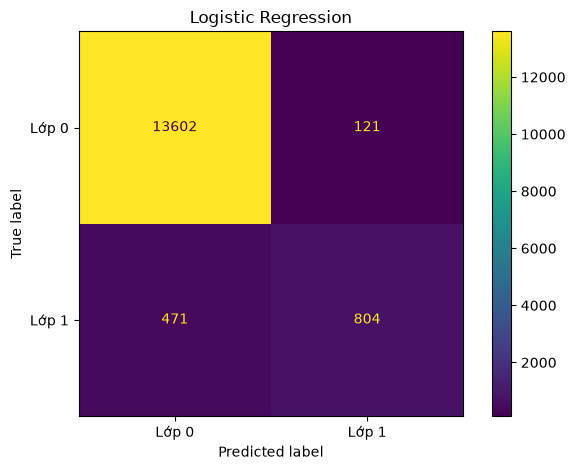

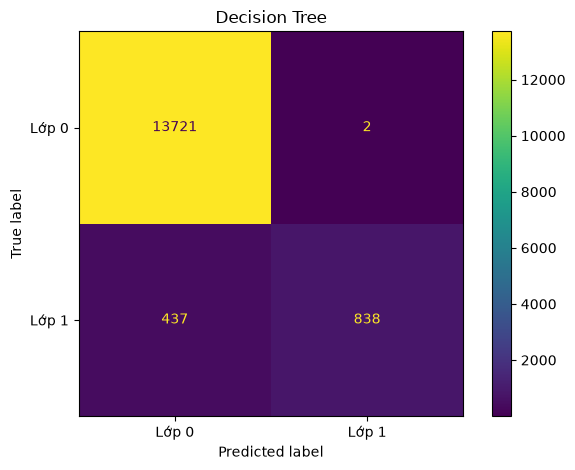

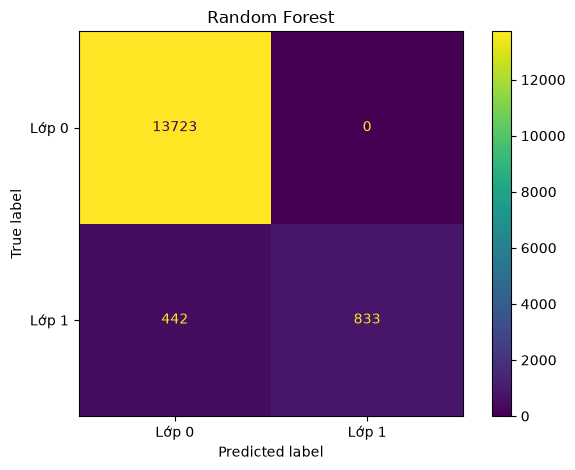

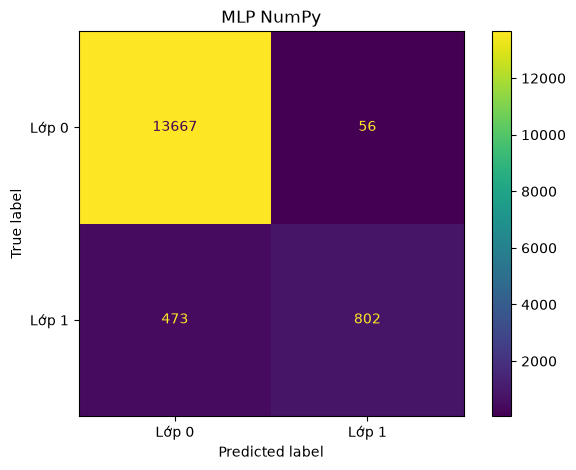

In [30]:
for name, score in test_scores.items():
    pred = (score >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Lớp 0", "Lớp 1"]).plot()
    plt.title(name)
    plt.tight_layout()
    plt.show()

## 20. Phân tích lỗi

Xem riêng **False Positive** và **False Negative**. Một mô hình có ít lỗi tổng cộng vẫn có thể bỏ sót nhiều mẫu lớp 1. Việc phân tích các dòng sai chỉ mô tả hành vi mô hình trên dữ liệu này, không giải thích nguyên nhân y khoa.

,FP,FN
Model,,
Logistic Regression,121,471
Decision Tree,2,437
Random Forest,0,442
MLP NumPy,56,473


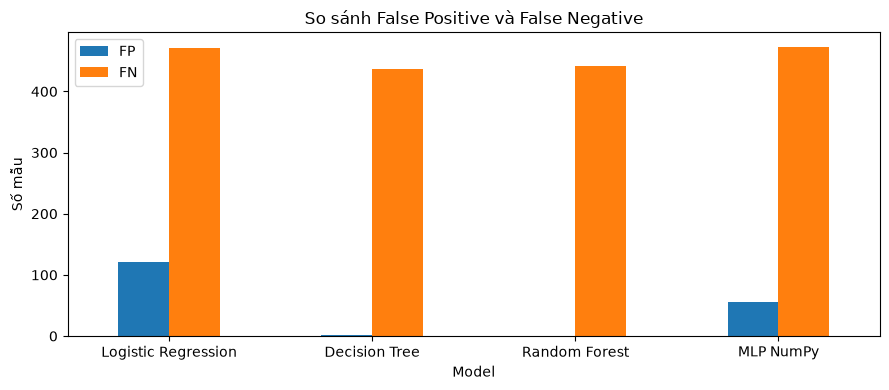

In [31]:
error_rows = []
for name, score in test_scores.items():
    pred = (score >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    error_rows.append({"Model": name, "FP": int(cm[0, 1]), "FN": int(cm[1, 0])})
error_df = pd.DataFrame(error_rows).set_index("Model")
display(error_df)
error_df.plot(kind="bar", figsize=(9, 4), rot=0)
plt.ylabel("Số mẫu")
plt.title("So sánh False Positive và False Negative")
plt.tight_layout()
plt.show()

**Nhận xét lỗi:** Decision Tree có 2 FP và 437 FN trên Test. MLP NumPy có 56 FP và 473 FN. Số FN vẫn đáng chú ý, nên kết quả này chưa đủ để sử dụng như một hệ thống chẩn đoán thực tế.

In [32]:
chosen_score = test_scores[best_model_name]
chosen_pred = (chosen_score >= 0.5).astype(int)
errors = X_test_raw.copy()
errors["Nhãn thật"] = y_test.to_numpy()
errors["Dự đoán"] = chosen_pred
errors["Điểm lớp 1"] = chosen_score
errors["Loại lỗi"] = np.where((errors["Nhãn thật"] == 1) & (errors["Dự đoán"] == 0), "FN",
                             np.where((errors["Nhãn thật"] == 0) & (errors["Dự đoán"] == 1), "FP", "Đúng"))
display(errors[errors["Loại lỗi"] != "Đúng"].head(10))

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,...,smoking_history,bmi,hbA1c_level,blood_glucose_level,cardio_risk,glucose_hba1c_interaction,Nhãn thật,Dự đoán,Điểm lớp 1,Loại lỗi
18200,2019,Male,80.0,District of Columbia,0,1,0,0,0,1,...,former,29.79,5.7,145,1,826.5,1,0,0.232584,FN
95742,2016,Male,74.0,Virginia,1,0,0,0,0,1,...,never,35.83,6.5,130,2,845.0,1,0,0.357383,FN
56766,2019,Male,46.0,Nebraska,0,0,1,0,0,0,...,ever,27.57,5.8,200,0,1160.0,1,0,0.024865,FN
46786,2019,Female,56.0,Michigan,0,0,1,0,0,1,...,not current,20.62,6.5,160,1,1040.0,1,0,0.158559,FN
17361,2019,Male,25.0,District of Columbia,0,0,0,0,1,0,...,No Info,55.99,5.8,145,0,841.0,1,0,0.004464,FN
14573,2019,Male,42.0,Delaware,0,0,0,1,0,0,...,never,27.32,6.1,140,0,854.0,1,0,0.006265,FN
1545,2019,Male,45.0,Alabama,1,0,0,0,0,1,...,never,33.08,5.8,200,1,1160.0,1,0,0.138655,FN
21331,2019,Male,76.0,Georgia,0,1,0,0,0,0,...,former,36.55,5.8,145,1,841.0,1,0,0.357383,FN
18328,2016,Male,57.0,Florida,0,0,0,1,0,0,...,never,40.52,6.0,126,1,756.0,1,0,0.357383,FN
2922,2019,Male,80.0,Alaska,0,0,0,1,0,1,...,current,27.32,6.1,126,2,768.6,1,0,0.232584,FN


## 21. Chọn mô hình

Mô hình đã được chọn theo Validation F1. Phần này báo cáo kết quả Test của mô hình đó và so sánh với MLP. Nếu DL không tốt nhất, vẫn giữ kết quả DL để giải thích; không được coi Deep Learning mặc nhiên tốt hơn ML.

In [33]:
best_row = test_results.set_index("Model").loc[best_model_name]
print("Mô hình được chọn:", best_model_name)
display(best_row.to_frame("Test").T.round(4))

mlp_row = test_results.set_index("Model").loc["MLP NumPy"]
print("F1 của MLP NumPy:", round(mlp_row["F1"], 4))
if mlp_row["F1"] > best_row["F1"]:
    print("MLP có Test F1 cao hơn mô hình đã chọn trong lần chạy này; không đổi lựa chọn theo Test.")
elif mlp_row["F1"] < best_row["F1"]:
    print("MLP có Test F1 thấp hơn mô hình đã chọn trong lần chạy này.")
else:
    print("Hai mô hình có Test F1 bằng nhau.")

Mô hình được chọn: Decision Tree


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Test,0.9707,0.9976,0.6573,0.7924,0.9704,0.848


F1 của MLP NumPy: 0.752
MLP có Test F1 thấp hơn mô hình đã chọn trong lần chạy này.
